# Correlations and Feature Importance

## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import VarianceThreshold

## Load Dataset

In [2]:
df = pd.read_csv('../data/processed/corn_belt_yield_weather_soil.csv', dtype={'fips':str})

In [3]:
df.shape

(24644, 106)

In [4]:
df.info(verbose=True, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24644 entries, 0 to 24643
Data columns (total 106 columns):
 #    Column                              Non-Null Count  Dtype  
---   ------                              --------------  -----  
 0    state_name                          24644 non-null  object 
 1    state_alpha                         24644 non-null  object 
 2    state_ansi                          24644 non-null  int64  
 3    county_ansi                         24644 non-null  int64  
 4    fips                                24644 non-null  object 
 5    county_name                         24644 non-null  object 
 6    year                                24644 non-null  int64  
 7    short_desc                          24644 non-null  object 
 8    unit_desc                           24644 non-null  object 
 9    statisticcat_desc                   24644 non-null  object 
 10   Value                               24644 non-null  float64
 11   latitude                  

In [5]:
df.head()

,state_name,state_alpha,state_ansi,county_ansi,fips,county_name,year,short_desc,unit_desc,statisticcat_desc,...,vp_mean_pa_m12,sand_pct_0_30cm,silt_pct_0_30cm,clay_pct_0_30cm,organic_matter_pct_0_30cm,ph_0_30cm,bulk_density_g_cm3_0_30cm,ksat_um_s_0_30cm,available_water_storage_cm_0_100cm,slope_pct
0,ILLINOIS,IL,17,11,17011,BUREAU,2025,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",BU / ACRE,YIELD,...,357.549355,12.94747,62.984117,24.068413,3.691334,6.516119,1.363566,11.164841,18.336345,4.666624
1,ILLINOIS,IL,17,11,17011,BUREAU,2024,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",BU / ACRE,YIELD,...,462.975000,12.94747,62.984117,24.068413,3.691334,6.516119,1.363566,11.164841,18.336345,4.666624
2,ILLINOIS,IL,17,11,17011,BUREAU,2023,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",BU / ACRE,YIELD,...,614.017097,12.94747,62.984117,24.068413,3.691334,6.516119,1.363566,11.164841,18.336345,4.666624
3,ILLINOIS,IL,17,11,17011,BUREAU,2022,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",BU / ACRE,YIELD,...,393.786774,12.94747,62.984117,24.068413,3.691334,6.516119,1.363566,11.164841,18.336345,4.666624
4,ILLINOIS,IL,17,11,17011,BUREAU,2021,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",BU / ACRE,YIELD,...,504.136452,12.94747,62.984117,24.068413,3.691334,6.516119,1.363566,11.164841,18.336345,4.666624


## Choose Analysis Years and Featuers

Since I will be doing some ML algorithims like Random Forest, I need to split the datset into a training set and testing set. I'll do the years 2000 - 2020 as my training set. It helps with my OCD for them to end in zeros, but it is really for having the most recent five years for evaluation. 

The years 2021 - 2025 will be used as prediction evaluation. 

The target variable is the corn yeild stored in `Value`

In [6]:
train = df[df['year'] <= 2020]
y_train = train['Value']

In [7]:
train.shape

(20480, 106)

In [8]:
train['year'].min()

2000

In [9]:
train['year'].max()

2020

### Weather Columns

In [10]:
weather_cols = ['prcp_total_mm_m01', 'prcp_total_mm_m02', 'prcp_total_mm_m03', 'prcp_total_mm_m04', 'prcp_total_mm_m06', 'prcp_total_mm_m05', 'prcp_total_mm_m07', 'prcp_total_mm_m08', 'prcp_total_mm_m09', 'prcp_total_mm_m10', 'prcp_total_mm_m11', 'prcp_total_mm_m12', 'radiation_total_mj_m2_m01', 'radiation_total_mj_m2_m02', 'radiation_total_mj_m2_m03', 'radiation_total_mj_m2_m04', 'radiation_total_mj_m2_m05', 'radiation_total_mj_m2_m06', 'radiation_total_mj_m2_m07', 'radiation_total_mj_m2_m08', 'radiation_total_mj_m2_m09', 'radiation_total_mj_m2_m10', 'radiation_total_mj_m2_m11', 'radiation_total_mj_m2_m12', 'dayl_mean_s_m01', 'dayl_mean_s_m02', 'dayl_mean_s_m03', 'dayl_mean_s_m04', 'dayl_mean_s_m05', 'dayl_mean_s_m06', 'dayl_mean_s_m07', 'dayl_mean_s_m08', 'dayl_mean_s_m09', 'dayl_mean_s_m10', 'dayl_mean_s_m11', 'dayl_mean_s_m12', 'swe_mean_kg_m2_m01', 'swe_mean_kg_m2_m02', 'swe_mean_kg_m2_m03', 'swe_mean_kg_m2_m04', 'swe_mean_kg_m2_m05', 'swe_mean_kg_m2_m06', 'swe_mean_kg_m2_m07', 'swe_mean_kg_m2_m08', 'swe_mean_kg_m2_m09', 'swe_mean_kg_m2_m10', 'swe_mean_kg_m2_m11', 'swe_mean_kg_m2_m12', 'tmax_mean_c_m01', 'tmax_mean_c_m02', 'tmax_mean_c_m03', 'tmax_mean_c_m04', 'tmax_mean_c_m05', 'tmax_mean_c_m06', 'tmax_mean_c_m07', 'tmax_mean_c_m08', 'tmax_mean_c_m09', 'tmax_mean_c_m10', 'tmax_mean_c_m11', 'tmax_mean_c_m12', 'tmin_mean_c_m01', 'tmin_mean_c_m02', 'tmin_mean_c_m03', 'tmin_mean_c_m04', 'tmin_mean_c_m05', 'tmin_mean_c_m06', 'tmin_mean_c_m07', 'tmin_mean_c_m08', 'tmin_mean_c_m09', 'tmin_mean_c_m10', 'tmin_mean_c_m11', 'tmin_mean_c_m12', 'vp_mean_pa_m01', 'vp_mean_pa_m02', 'vp_mean_pa_m03', 'vp_mean_pa_m04', 'vp_mean_pa_m05', 'vp_mean_pa_m06', 'vp_mean_pa_m07', 'vp_mean_pa_m08', 'vp_mean_pa_m09', 'vp_mean_pa_m10', 'vp_mean_pa_m11', 'vp_mean_pa_m12']

### Soil Columns

In [11]:
soil_cols = ['sand_pct_0_30cm', 'silt_pct_0_30cm', 'clay_pct_0_30cm', 'organic_matter_pct_0_30cm', 'ph_0_30cm', 'bulk_density_g_cm3_0_30cm', 'ksat_um_s_0_30cm', 'available_water_storage_cm_0_100cm', 'slope_pct']

### Combine Weather and Soil Columns

In [12]:
environment_cols = weather_cols + soil_cols

### Context Columns

In [13]:
context_cols = ['year', 'latitude', 'longitude']

## Remove Features with all zeros

I have three columns with values of all zeros `swe_mean_kg_m2_m07`, `swe_mean_kg_m2_m08`, and `swe_mean_kg_m2_m09`. These are the snow water equivalent for July, August, and September. Snow doesn't happen in these months in our dataset, so it is best to remove these constant value featuers as it will mess with our correlations and machine learning algorithms later on.

Using a variance threshold of zero will remove the features with 0 variance in them. 

In [14]:
len(environment_cols)

93

In [15]:
temp_cols = environment_cols

In [16]:
variance_filter = VarianceThreshold(threshold=0.0)
variance_filter.fit(train[temp_cols])

,"threshold threshold: float, default=0Features with a training-set variance lower than this threshold willbe removed. The default is to keep all features with non-zero variance,i.e. remove the features that have the same value in all samples.",0.0


In [17]:
environment_cols = variance_filter.get_feature_names_out().tolist()

In [18]:
for col in temp_cols:
    if col not in environment_cols:
        print(f"Removed: {col}")

Removed: swe_mean_kg_m2_m07
Removed: swe_mean_kg_m2_m08
Removed: swe_mean_kg_m2_m09


In [19]:
len(environment_cols)

90

## Pearson Correlation

Pearson Correlation Coefficient measures the strength and direction between two variables. Our variables are our environment variables and the corn yield. The Pearson Correlation ranges from -1 to 1. A value closer to 1 represeents a strong positive correlation, and a value closer to -1 represents a strong negative correlation. A value of 0 means that there is not a linear relationship between the two variables. 

[https://www.ebsco.com/research-starters/science/pearson-correlation-coefficient-pcc](https://www.ebsco.com/research-starters/science/pearson-correlation-coefficient-pcc)

In [20]:
pearson = train[environment_cols].corrwith(y_train, method='pearson')
pearson_results = pearson.to_frame(name='Pearson')
pearson_results

,Pearson
prcp_total_mm_m01,0.033760
prcp_total_mm_m02,0.070547
prcp_total_mm_m03,0.060757
prcp_total_mm_m04,0.096559
prcp_total_mm_m06,0.224031
...,...
ph_0_30cm,-0.020845
bulk_density_g_cm3_0_30cm,0.064019
ksat_um_s_0_30cm,-0.054114
available_water_storage_cm_0_100cm,0.298081


We have some negative values. Right now, we only care about which features are the most important even if it has a negative correlations. So we will also create a dataframe that is the absolute value of the pearson correlations. Doing the absolute value will make positive and negative relationships equallly representative.

In [21]:
pearson_results['Pearson_abs'] = pearson.abs().to_frame()
pearson_results

,Pearson,Pearson_abs
prcp_total_mm_m01,0.033760,0.033760
prcp_total_mm_m02,0.070547,0.070547
prcp_total_mm_m03,0.060757,0.060757
prcp_total_mm_m04,0.096559,0.096559
prcp_total_mm_m06,0.224031,0.224031
...,...,...
ph_0_30cm,-0.020845,0.020845
bulk_density_g_cm3_0_30cm,0.064019,0.064019
ksat_um_s_0_30cm,-0.054114,0.054114
available_water_storage_cm_0_100cm,0.298081,0.298081


### Sort values from strongest to weakest features

In [22]:
pearson_results = pearson_results.sort_values('Pearson_abs', ascending=False)
pearson_results

,Pearson,Pearson_abs
tmax_mean_c_m07,-0.312787,0.312787
available_water_storage_cm_0_100cm,0.298081,0.298081
radiation_total_mj_m2_m06,-0.295676,0.295676
tmax_mean_c_m08,-0.285611,0.285611
prcp_total_mm_m07,0.250252,0.250252
...,...,...
tmin_mean_c_m08,-0.006735,0.006735
radiation_total_mj_m2_m10,0.006218,0.006218
tmax_mean_c_m06,0.005074,0.005074
clay_pct_0_30cm,0.004399,0.004399


### Let's display the top 15 features

In [23]:
top_pearson = pearson_results.head(15)
top_pearson

,Pearson,Pearson_abs
tmax_mean_c_m07,-0.312787,0.312787
available_water_storage_cm_0_100cm,0.298081,0.298081
radiation_total_mj_m2_m06,-0.295676,0.295676
tmax_mean_c_m08,-0.285611,0.285611
prcp_total_mm_m07,0.250252,0.250252
prcp_total_mm_m06,0.224031,0.224031
vp_mean_pa_m06,0.222869,0.222869
radiation_total_mj_m2_m05,-0.195680,0.195680
vp_mean_pa_m09,0.189245,0.189245
tmin_mean_c_m06,0.188767,0.188767


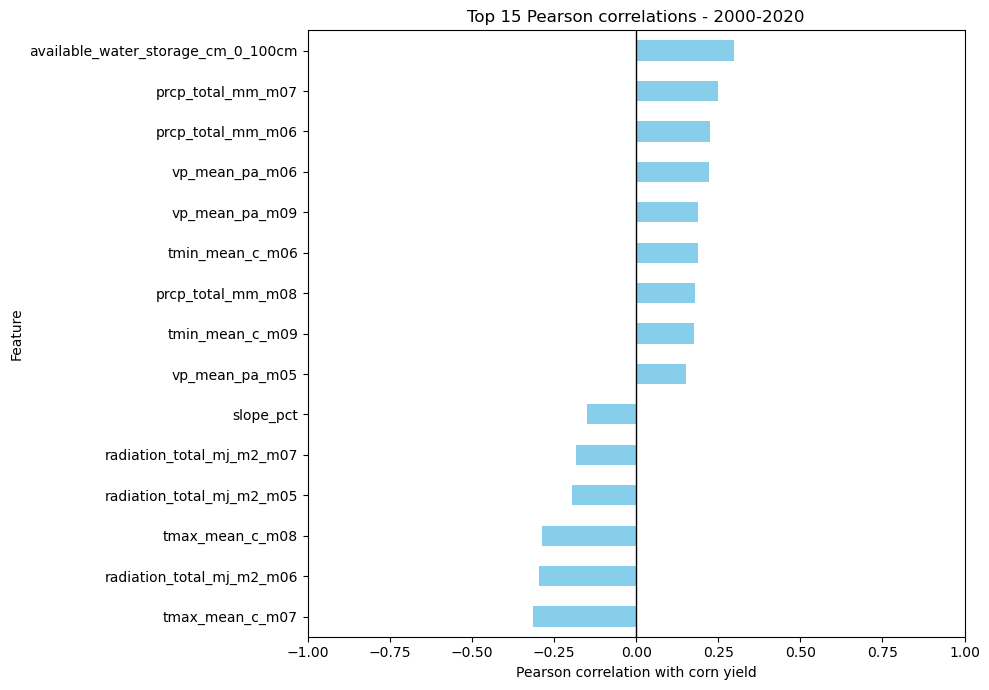

In [24]:
top_pearson['Pearson'].sort_values().plot.barh(figsize=(10, 7), color='skyblue')
plt.axvline(0, color="black", linewidth=1)
plt.xlim(-1,1)
plt.xlabel("Pearson correlation with corn yield")
plt.ylabel("Feature")
plt.title("Top 15 Pearson correlations - 2000-2020")
plt.tight_layout()
plt.show()

July's maximum temperature (`tmax_mean_c_m07`) had the largest absolute pearson correlation with yield (`-0.312787`). Then it was available water storage (`0.298081`) and Solar Radiation in June (`-0.295676`).

This means that the higher the temperature in July and more radiation in June, the lower the corn yields from 2000-2020. The more water storage available associates with higher yield. 

## Spearman Correlation

Spearman Correlation is a bit different from Pearson because it is computed on ranks and not their original mesurements. This means it can detect consitently increasing or descreasing relationship that are not straight lines. It's range is also form -1 to +1.

In [25]:
spearman = train[environment_cols].corrwith(y_train, method='spearman')
spearman_results = spearman.to_frame(name='Spearman')
spearman_results

,Spearman
prcp_total_mm_m01,0.066886
prcp_total_mm_m02,0.040632
prcp_total_mm_m03,0.086980
prcp_total_mm_m04,0.110627
prcp_total_mm_m06,0.233184
...,...
ph_0_30cm,0.039447
bulk_density_g_cm3_0_30cm,0.073857
ksat_um_s_0_30cm,-0.053880
available_water_storage_cm_0_100cm,0.332756


In [26]:
spearman_results['Spearman_abs'] = spearman.abs().to_frame()
spearman_results

,Spearman,Spearman_abs
prcp_total_mm_m01,0.066886,0.066886
prcp_total_mm_m02,0.040632,0.040632
prcp_total_mm_m03,0.086980,0.086980
prcp_total_mm_m04,0.110627,0.110627
prcp_total_mm_m06,0.233184,0.233184
...,...,...
ph_0_30cm,0.039447,0.039447
bulk_density_g_cm3_0_30cm,0.073857,0.073857
ksat_um_s_0_30cm,-0.053880,0.053880
available_water_storage_cm_0_100cm,0.332756,0.332756


### Sort values from strongest to weakest features

In [27]:
spearman_results = spearman_results.sort_values('Spearman_abs', ascending=False)
spearman_results

,Spearman,Spearman_abs
available_water_storage_cm_0_100cm,0.332756,0.332756
tmax_mean_c_m08,-0.279351,0.279351
tmax_mean_c_m07,-0.266988,0.266988
prcp_total_mm_m07,0.253974,0.253974
radiation_total_mj_m2_m06,-0.242167,0.242167
...,...,...
vp_mean_pa_m07,0.004023,0.004023
radiation_total_mj_m2_m10,-0.003575,0.003575
swe_mean_kg_m2_m12,0.001989,0.001989
swe_mean_kg_m2_m04,-0.001116,0.001116


### Let's display the top 15 features

In [28]:
top_spearman = spearman_results.head(15)
top_spearman

,Spearman,Spearman_abs
available_water_storage_cm_0_100cm,0.332756,0.332756
tmax_mean_c_m08,-0.279351,0.279351
tmax_mean_c_m07,-0.266988,0.266988
prcp_total_mm_m07,0.253974,0.253974
radiation_total_mj_m2_m06,-0.242167,0.242167
prcp_total_mm_m06,0.233184,0.233184
prcp_total_mm_m08,0.186332,0.186332
vp_mean_pa_m06,0.180242,0.180242
radiation_total_mj_m2_m05,-0.172291,0.172291
slope_pct,-0.160714,0.160714


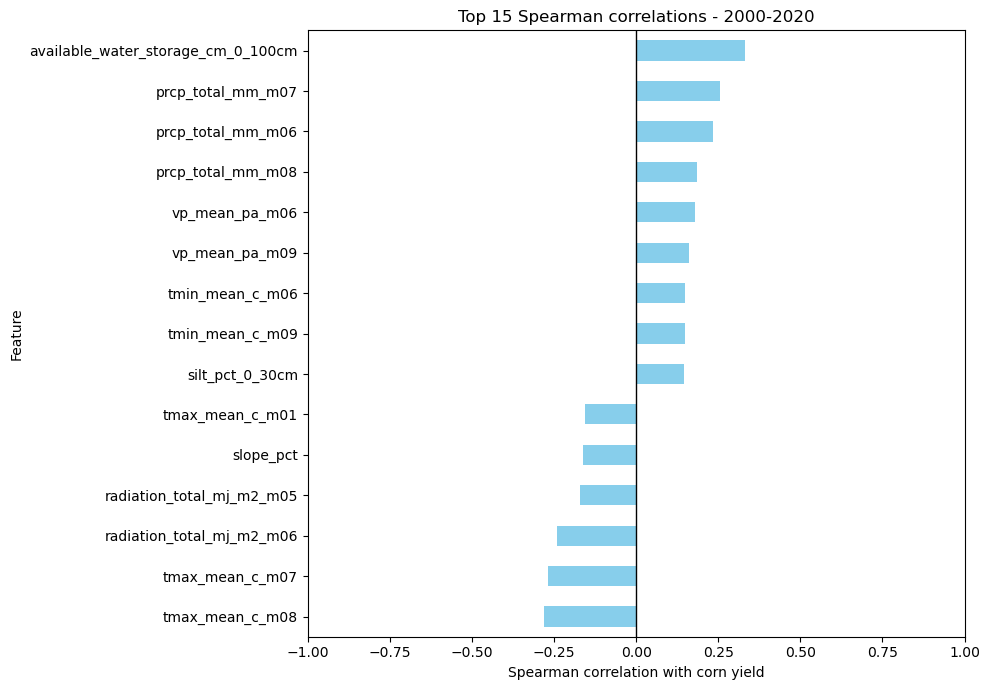

In [29]:
top_spearman['Spearman'].sort_values().plot.barh(figsize=(10, 7), color='skyblue')
plt.axvline(0, color="black", linewidth=1)
plt.xlim(-1,1)
plt.xlabel("Spearman correlation with corn yield")
plt.ylabel("Feature")
plt.title("Top 15 Spearman correlations - 2000-2020")
plt.tight_layout()
plt.show()

The Spearman Correlation had the available water storage as having the highest correlation with yield (`0.332756`). Then it was August maximum temperature (`	-0.279351`) and July maximum tempearture (`-0.266988`). This means that the soil having greater water storage associated with higher yields while July and August maximum temps are associated with lower yields.

Pearson and Spearman both identified the same top five features even though they were in a different order (`available_water_storage_cm_0_100cm`, `tmax_mean_c_m08`, `tmax_mean_c_m07`, `prcp_total_mm_m07`, `radiation_total_mj_m2_m06`). This makes these features good candidates for futher investigation. 

## Random Forest Feature Importance

The Random Forest Algorithm combines many decision trees to predict a final value, which is our corn yield.

First, I will fit the model using the same features we used for the correlations as inputs.

The model will assign importance scores based on how much each feature helps reduce prediction error when splitting the training data. A higher score indicates a greater contribution to fitting that data.

In [30]:
X_train = train[environment_cols]
X_train.shape

(20480, 90)

I am just using the scikit-learn default Random Forest parameters. Later on I will adjust the model with different settings to assess prediction accurary and ranking stability. For now I am just using a `random_state` of `110` so the analysis can be reproducable.

In [31]:
forest = RandomForestRegressor(random_state=110)

In [32]:
forest

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [33]:
forest.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [34]:
rf_results = pd.DataFrame({"Random Forest": forest.feature_importances_},index=X_train.columns)

rf_results = rf_results.sort_values("Random Forest", ascending=False)

rf_results.head(15)

,Random Forest
tmax_mean_c_m07,0.143678
available_water_storage_cm_0_100cm,0.097592
tmin_mean_c_m06,0.090133
tmax_mean_c_m08,0.075839
ksat_um_s_0_30cm,0.046068
vp_mean_pa_m06,0.045691
prcp_total_mm_m07,0.020773
tmin_mean_c_m09,0.017151
organic_matter_pct_0_30cm,0.015266
bulk_density_g_cm3_0_30cm,0.014814


In [35]:
top_rf = rf_results.head(15)

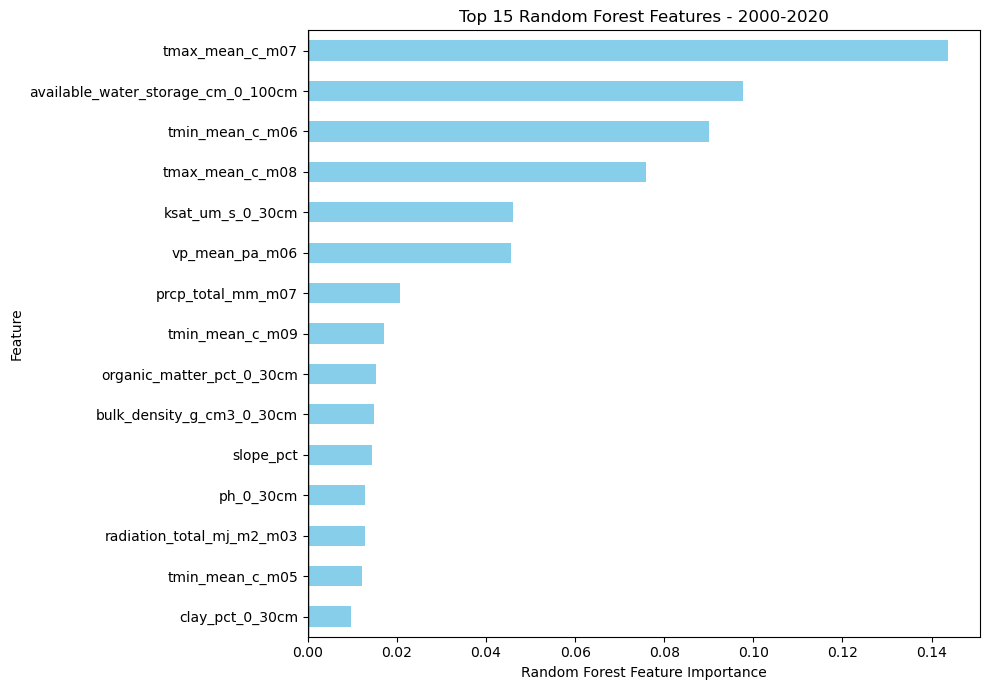

In [36]:
top_rf['Random Forest'].sort_values().plot.barh(figsize=(10, 7), color='skyblue')
plt.axvline(0, color="black", linewidth=1)
plt.xlim(left=0)
plt.xlabel("Random Forest Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Random Forest Features - 2000-2020")
plt.tight_layout()
plt.show()

The maximum temperature in July had the highest Random Forest importance score of `0.143678`. Then it was the available water storage (`0.097592`) and the Minimum temerperature in June (`0.090133`). These features are the ones that contributed the most to making the variation in yield the smallest within the decision trees. All of the scores sum up to 1 across all 90 features and describe the relative importance within this Random Forest Model. These importance scores are based on the training data and the evaluation on later years is still needed to determine their usefulness for prediction.

July maximum temperature and available water storage ranked high in the Pearson and Spearman correlations as well as the random forest. June minimum temperature and hydraulic conductivity ranked higher in the Random Forest than it did in the correlations. These differences might show that the model is considering features together and capturing more complex relationships.

## Comparing Feature Rankings

In [37]:
ranking_comparison = pd.DataFrame({
    "Pearson": pearson_results.head(15).index.tolist(),
    "Spearman": spearman_results.head(15).index.tolist(),
    "Random Forest": rf_results.head(15).index.tolist()
})

In [38]:
ranking_comparison.index = range(1, 16)
ranking_comparison.index.name = "Rank"
ranking_comparison

,Pearson,Spearman,Random Forest
Rank,,,
1,tmax_mean_c_m07,available_water_storage_cm_0_100cm,tmax_mean_c_m07
2,available_water_storage_cm_0_100cm,tmax_mean_c_m08,available_water_storage_cm_0_100cm
3,radiation_total_mj_m2_m06,tmax_mean_c_m07,tmin_mean_c_m06
4,tmax_mean_c_m08,prcp_total_mm_m07,tmax_mean_c_m08
5,prcp_total_mm_m07,radiation_total_mj_m2_m06,ksat_um_s_0_30cm
6,prcp_total_mm_m06,prcp_total_mm_m06,vp_mean_pa_m06
7,vp_mean_pa_m06,prcp_total_mm_m08,prcp_total_mm_m07
8,radiation_total_mj_m2_m05,vp_mean_pa_m06,tmin_mean_c_m09
9,vp_mean_pa_m09,radiation_total_mj_m2_m05,organic_matter_pct_0_30cm


## Findings

The featuers`available_water_storage_cm_0_100cm`, `prcp_total_mm_m07`, `slope_pct`, `tmax_mean_c_m07`, `tmax_mean_c_m08`, `tmin_mean_c_m06`, `tmin_mean_c_m09`, and `vp_mean_pa_m06`are in all three of our measurements. 

Pearson Correlation showed that July's maximum temperature had the largest absolute correlation with yield (`-0.312787`).

Spearman Correlation showed taht the available water storage had the largest absolute correlation with yield (`0.332756`)

Random Forest showed that July's maximum temperature had the highest importance score  (`0.143678`).

Pearson and Spearman share most of their features, but when adding the Random Forest, only 8 of the featuers are all the same. Avalable water storage and the temperatures in the summer months were consistently towards the top of all of the methods. These make them candidates for further investigation.